# Terminal map — global catalog

Starting point for terminal deep-dives. Built from DuckDB trades via:

```bash
python build_terminal_catalog.py
```

**Tables**
- `data/derived/terminals.parquet` — one row per installation
- `data/derived/terminal_products.parquet` — product mix by direction
- `data/derived/terminal_partners.parquet` — top partner countries
- `data/derived/terminals_enrichment_template.csv` — fill later: demand centers, pipelines, lat/lon

**Roles:** `export_only` / `import_only` / `hub` (both).

Later layers: demand centers, regions covered, pipeline connectivity, arb/margins.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
DERIVED = ROOT / "data" / "derived"

terminals = pd.read_parquet(DERIVED / "terminals.parquet")
products = pd.read_parquet(DERIVED / "terminal_products.parquet")
partners = pd.read_parquet(DERIVED / "terminal_partners.parquet")

print(len(terminals), "terminals")
print(terminals["role"].value_counts())
terminals.head()

3540 terminals
role
hub            2543
import_only     507
export_only     490
Name: count, dtype: int64


,terminal_key,installation_id,installation_name,country,zone,continent,trading_region,role,looks_like_refinery,export_mb,...,demand_centers,regions_covered,pipeline_connected,pipeline_names,lat,lon,notes,catalog_built_at,status_filter,exclude_crude
0,1328,1328,Juaymah,Saudi Arabia,Ras Tanura,Asia,Mideast Gulf,export_only,False,16122.388862,...,None,None,None,None,None,None,None,2026-07-16T17:00:15.619163+00:00,Delivered,False
1,1368,1368,Al Basrah,Iraq,Al Basrah,Asia,Mideast Gulf,export_only,False,12208.991298,...,None,None,None,None,None,None,None,2026-07-16T17:00:15.619163+00:00,Delivered,False
2,1266,1266,Jamnagar Refinery,India,Sikka,Asia,South-Central Asia,hub,True,3386.976171,...,None,None,None,None,None,None,None,2026-07-16T17:00:15.619163+00:00,Delivered,False
3,1329,1329,Ras Tanura,Saudi Arabia,Ras Tanura,Asia,Mideast Gulf,hub,False,7791.301498,...,None,None,None,None,None,None,None,2026-07-16T17:00:15.619163+00:00,Delivered,False
4,1847,1847,Mina Al-Ahmadi,Kuwait,Mina Al-Ahmadi,Asia,Mideast Gulf,export_only,False,6335.494634,...,None,None,None,None,None,None,None,2026-07-16T17:00:15.619163+00:00,Delivered,False


## Universe snapshot

,n_terminals,total_mb
country,,
China,283,56890.052274
United States,343,46468.155555
Saudi Arabia,28,39697.598536
Russian Federation,70,28139.804856
India,63,27375.264394
Brazil,122,25401.900850
United Arab Emirates,40,21229.900342
South Korea,55,20205.338661
Japan,134,18222.976540


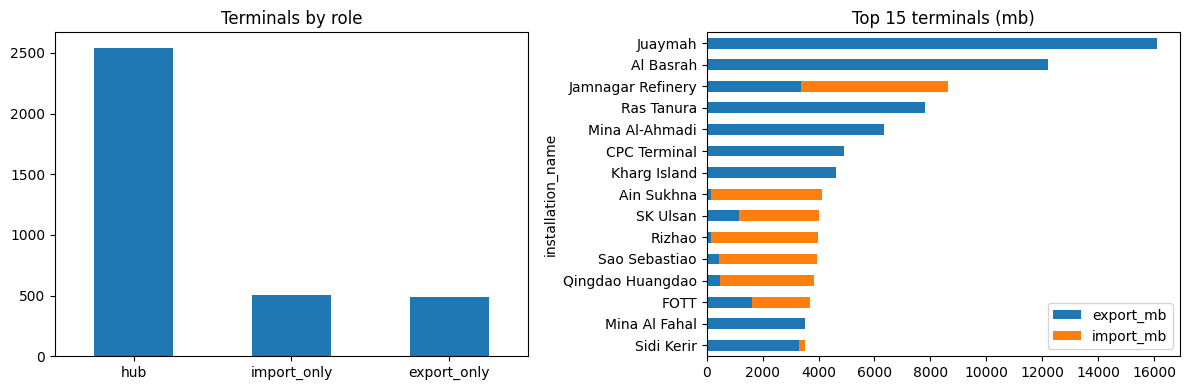

In [2]:
by_country = (
    terminals.groupby("country", dropna=False)
    .agg(n_terminals=("terminal_key", "count"), total_mb=("total_mb", "sum"))
    .sort_values("total_mb", ascending=False)
    .head(20)
)
display(by_country)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
terminals["role"].value_counts().plot(kind="bar", ax=axes[0], title="Terminals by role")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
(
    terminals.nlargest(15, "total_mb")
    .set_index("installation_name")[["export_mb", "import_mb"]]
    .plot(kind="barh", stacked=True, ax=axes[1], title="Top 15 terminals (mb)")
)
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## Terminal deep-dive helper

Pick a terminal by name (substring match) or `terminal_key`.

In [3]:
def find_terminals(query: str, n: int = 15) -> pd.DataFrame:
    q = query.lower()
    hit = terminals[
        terminals["installation_name"].fillna("").str.lower().str.contains(q, regex=False)
        | terminals["country"].fillna("").str.lower().str.contains(q, regex=False)
    ]
    return hit.nlargest(n, "total_mb")[
        [
            "terminal_key",
            "installation_name",
            "country",
            "zone",
            "role",
            "export_mb",
            "import_mb",
            "total_mb",
            "looks_like_refinery",
        ]
    ]


def deep_dive(terminal_key: str):
    meta = terminals.loc[terminals["terminal_key"] == terminal_key]
    if meta.empty:
        print("not found:", terminal_key)
        return
    row = meta.iloc[0]
    print("=" * 72)
    print(row["installation_name"], "|", row["country"], "|", row["role"])
    print(
        f"export {row['export_mb']:.1f} mb · import {row['import_mb']:.1f} mb · "
        f"zone={row['zone']} · trading_region={row['trading_region']}"
    )
    print(
        "Enrichment placeholders —",
        f"demand_centers={row['demand_centers']}, "
        f"regions_covered={row['regions_covered']}, "
        f"pipeline_connected={row['pipeline_connected']}",
    )
    print("=" * 72)

    prod = products[products["terminal_key"] == terminal_key].copy()
    print("\nProducts")
    display(
        prod.pivot_table(
            index=["family", "product"], columns="direction", values="mb", aggfunc="sum"
        )
        .fillna(0)
        .sort_values(by=list(prod["direction"].unique()), ascending=False)
        .head(25)
    )

    part = partners[partners["terminal_key"] == terminal_key].copy()
    print("\nPartner countries")
    display(part.sort_values("mb", ascending=False).head(30))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, direction, title in [
        (axes[0], "export", "Exports by product (mb)"),
        (axes[1], "import", "Imports by product (mb)"),
    ]:
        sub = prod[prod["direction"] == direction].nlargest(10, "mb")
        if sub.empty:
            ax.set_title(title + " — none")
            ax.axis("off")
            continue
        sub.set_index("product")["mb"].plot(kind="barh", ax=ax, title=title)
        ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
    return {"meta": row, "products": prod, "partners": part}


# Examples
display(find_terminals("Cartagena"))
display(find_terminals("Sines"))
display(find_terminals("Fos"))

,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
71,1243,Repsol Cartagena Refinery,Spain,Cartagena,hub,403.000683,1243.839199,1646.839882,True
2102,2567,Oiltank. Cartagena,Colombia,Cartagena (Colombia),hub,0.119915,6.106727,6.226642,False
2577,2568,Vopak Cartagena,Colombia,Cartagena (Colombia),hub,0.917290,1.131467,2.048757,False
2705,3427,Algranel Cartagena,Colombia,Cartagena (Colombia),hub,0.160720,1.222067,1.382787,False
2810,8474,Plexaport Cartagena,Colombia,Cartagena (Colombia),hub,0.668231,0.362173,1.030404,False
3465,12490,Timab Cartagena,Spain,Cartagena,import_only,0.000000,0.042120,0.042120,False


,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
192,1261,Sines Refinery,Portugal,Sines,hub,4.283640,730.295617,734.579257,True
243,2457,Sines Products,Portugal,Sines,hub,462.039172,128.031638,590.070810,False


,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
42,1274,Fos Sur Mer,France,Fos,hub,116.803629,2021.552742,2138.356371,False
2293,8837,CNPC Foshan Asphalt Terminal,China,Gaoming,hub,0.190928,3.906043,4.096971,False
2970,349,ArcelorMittal Fos Sur Mer,France,Fos,hub,0.638112,0.003742,0.641854,False


Repsol Cartagena Refinery | Spain | hub
export 403.0 mb · import 1243.8 mb · zone=Cartagena · trading_region=MED Zone (MED Sea+Black Sea)
Enrichment placeholders — demand_centers=None, regions_covered=None, pipeline_connected=None

Products


direction                                export       import
family             product                                  
Light Ends         Naphtha           144.175300     3.354084
Middle Distillates Gasoil             81.006131    10.813139
                   Diesel             69.911347     4.446994
Clean              (blank)            22.684618     4.009628
Middle Distillates Jet                20.382355     1.821788
Light Ends         Gasoline           20.353504     5.604464
DPP                FO                 12.796724    31.063450
Light Ends         Blending Comps     12.630019     4.808596
DPP                Dirty Feedstocks   10.012553    24.129170
Dirty              (blank)             2.907062     9.078360
DPP                (blank)             2.435153    25.362689
Middle Distillates (blank)             0.979861     0.000000
DPP                Bitumen/Asphalt     0.973475     0.000000
Dirty              Crude               0.577722  1106.148476
Light Ends         (blank)             0.574206     0.000000
DPP                Specialities        0.206254     0.000000
                   Slurry              0.200487     0.000000
                   SRFO                0.110014    11.899220
Middle Distillates Kerosene            0.034411     0.026630
DPP                CBFS                0.032524     0.106064
Middle Distillates Cycle Oil           0.016963     0.581653
Dirty              Condensate          0.000000     0.289249
Light Ends         Clean Condensate    0.000000     0.207362
DPP                Coal Tar            0.000000     0.088183


Partner countries


,terminal_key,installation_id,installation_name,direction,partner_country,mb
314,1243,1243,Repsol Cartagena Refinery,import_from,Mexico,270.784433
436,1243,1243,Repsol Cartagena Refinery,import_from,Egypt,218.819447
870,1243,1243,Repsol Cartagena Refinery,import_from,Iraq,121.668268
873,1243,1243,Repsol Cartagena Refinery,export_to,Spain,121.449012
1111,1243,1243,Repsol Cartagena Refinery,import_from,Russian Federation,99.416037
1330,1243,1243,Repsol Cartagena Refinery,import_from,Brazil,85.194123
1474,1243,1243,Repsol Cartagena Refinery,import_from,United States,76.999388
1826,1243,1243,Repsol Cartagena Refinery,import_from,Libya,62.868568
2184,1243,1243,Repsol Cartagena Refinery,import_from,Spain,50.932787
2231,1243,1243,Repsol Cartagena Refinery,import_from,Venezuela,49.666868


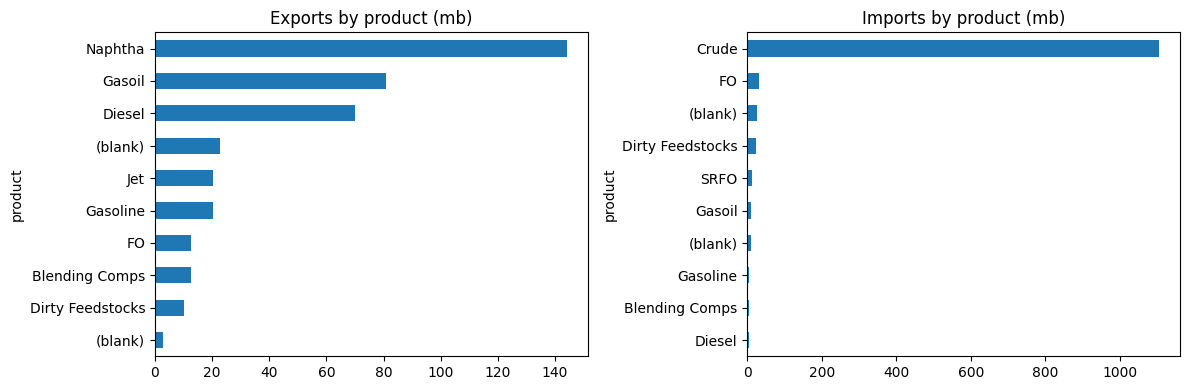

In [4]:
# Pick a terminal_key from find_terminals() and deep-dive
example = find_terminals("Cartagena", n=1)
if len(example):
    deep_dive(example.iloc[0]["terminal_key"])

## Country slice (e.g. Spain / France / Portugal)

In [5]:
FOCUS = ["Spain", "France", "Portugal"]
focus = terminals[terminals["country"].isin(FOCUS)].copy()
print(len(focus), "terminals in", FOCUS)
display(
    focus.nlargest(25, "total_mb")[
        [
            "installation_name",
            "country",
            "role",
            "export_mb",
            "import_mb",
            "total_mb",
            "looks_like_refinery",
        ]
    ]
)

141 terminals in ['Spain', 'France', 'Portugal']


,installation_name,country,role,export_mb,import_mb,total_mb,looks_like_refinery
42,Fos Sur Mer,France,hub,116.803629,2021.552742,2138.356371,False
68,Le Havre,France,hub,105.885646,1560.755731,1666.641377,False
71,Repsol Cartagena Refinery,Spain,hub,403.000683,1243.839199,1646.839882,True
92,Gibraltar-San Roque Refinery,Spain,hub,387.079955,953.760985,1340.840940,True
139,Tarragona Refinery,Spain,hub,173.389864,773.133574,946.523438,True
171,Donges Refinery,France,hub,225.623322,573.090854,798.714176,True
173,La Rabida,Spain,hub,59.797778,734.313412,794.111190,False
187,Repsol Petronor Refinery,Spain,hub,8.199128,737.263728,745.462856,True
192,Sines Refinery,Portugal,hub,4.283640,730.295617,734.579257,True
243,Sines Products,Portugal,hub,462.039172,128.031638,590.070810,False


## Enrichment workflow (next)

1. Edit `data/derived/terminals_enrichment_template.csv` (or a filtered copy) with:
   - `demand_centers` — cities/industrial basins served
   - `regions_covered` — hinterland / PADD-like region
   - `pipeline_connected` — True/False/Unknown
   - `pipeline_names` — e.g. CLH, SPSE, …
   - `lat` / `lon` — for maps
2. Merge back on `terminal_key`.
3. Later: join arb/margin signals to the same keys.

Kpler alone cannot answer pipeline connectivity or true demand centers — those need
external/reference data layered onto this activity map.